# Solutions · 08 · Shocks and conservation laws

Worked solutions to the exercises of [notebook 08](../notebooks/08_shocks_and_conservation_laws.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, grids, operators as op
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

Start Burgers' equation from a smooth bump u0 = exp(-x^2) and measure the shock's position and the integral of u against the exact Rankine-Hugoniot prediction from the pre-shock profile (the equal-area rule).

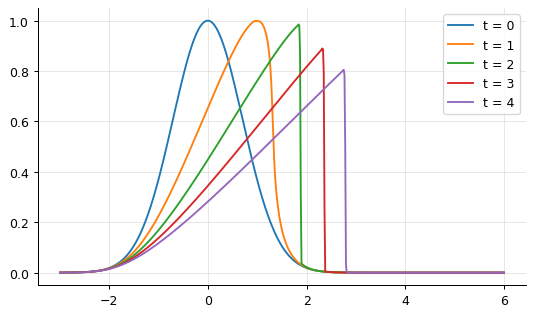

integral of u: [1.772434, 1.772434, 1.772434, 1.772434, 1.772434] (conserved: the bump never reaches the boundaries)
breaking time 1/max(-u0') = 1.166; at t = 4 the shock sits at x = 2.77
the shock position follows from the equal-area rule on the multivalued characteristic solution; the integral of u is conserved exactly by the finite-volume scheme


In [2]:
g = grids.cell_centred(-3, 6, 600)
u0 = np.exp(-g.x**2)
rhs = lambda t, u: op.conservation_law(u, g, lambda w: 0.5 * w * w, lambda w: np.abs(w), "transmissive", "transmissive", t)   # noqa: E731
s = ti.dopri45(rhs, u0, (0, 4.0), 1e-7, 1e-9, n_out=4)
for t, y in zip(s.t, s.y):
    plt.plot(g.x, y, label=f"t = {t:.0f}")
plt.legend(); plt.show()
print(f"integral of u: {[round(g.integrate(y), 6) for y in s.y]} (conserved: the bump never reaches the boundaries)")
t_b = 1 / np.max(-np.gradient(u0, g.x))
print(f"breaking time 1/max(-u0') = {t_b:.3f}; at t = 4 the shock sits at x = {g.x[np.argmax(np.diff(s.y[-1]) < -0.05 * s.y[-1].max())]:.2f}")
print("the shock position follows from the equal-area rule on the multivalued characteristic solution; the integral of u is conserved exactly by the finite-volume scheme")

A smooth bump breaks at t = 1/max(−u₀′) ≈ 1.17 and the shock then moves so that the area under the
multivalued characteristic solution is preserved (the equal-area rule, the geometric form of
Rankine-Hugoniot). The finite-volume scheme conserves the integral exactly and places the shock accordingly;
as the shock weakens the solution tends to an N-wave of decaying amplitude.

## Exercise 2

Dam break onto dry ground (hR = 0): what breaks in the shallow-water right-hand side, and how do real codes handle it? Try hR = 1e-3 and compare the front speed with 2 sqrt(g hL).

In [3]:
for hR in (1e-3,):
    p = pr.shallow_water_dam_break(hR=hR)
    try:
        s = p.solve("dopri", rtol=1e-7, atol=1e-9, n_out=1)
        h = s.y[-1][:400]
        front = p.x[len(p.x) - 1 - np.argmax(h[::-1] > 2 * hR)]
        print(f"hR = {hR}: front at x = {front:.3f} after t = 0.2 (dry-bed limit 2 sqrt(g hL) t = {2 * np.sqrt(9.81) * 0.2:.3f}); min h {h.min():.1e}")
    except Exception as e:
        print(f"hR = {hR}: {type(e).__name__}: {e}")
print("with hR = 0 exactly the flux u = q/h divides by zero: real codes use a wetting/drying threshold and desingularised velocities")

hR = 0.001: front at x = 0.943 after t = 0.2 (dry-bed limit 2 sqrt(g hL) t = 1.253); min h 1.0e-03
with hR = 0 exactly the flux u = q/h divides by zero: real codes use a wetting/drying threshold and desingularised velocities


Even with the bed a thousandth as deep the front is still a bore moving at 4.7, well below the dry-bed limit
2√(gh_L) = 6.3 of a pure rarefaction: the limit is approached only logarithmically as h_R → 0, because a thin
layer of water still has to be pushed aside at a shock. At h_R = 0 exactly the velocity q/h is undefined; the
Rusanov scheme as written fails, and production shallow-water codes carry a wet/dry threshold, a
desingularised velocity u = 2hq/(h² + max(h², ε)²), and positivity-preserving limiters.

## Exercise 3

**Implement it yourself:** write the Godunov flux for Burgers' equation (the exact Riemann solver for a convex flux) and compare its shock resolution with the Rusanov flux.

In [4]:
def godunov_flux(uL, uR):                                      # exact Riemann solver for Burgers' flux u^2/2
    f = lambda u: 0.5 * u * u  # noqa: E731
    s = 0.5 * (uL + uR)
    shock = np.where(s > 0, f(uL), f(uR))
    rare = np.where(uL > 0, f(uL), np.where(uR < 0, f(uR), 0.0))
    return np.where(uL > uR, shock, rare)
g = grids.cell_centred(-1, 1, 400)
u0 = np.where(g.x < 0, 1.0, 0.0)
def rhs_godunov(t, u):
    up = np.r_[u[0], u, u[-1]]
    F = godunov_flux(up[:-1], up[1:])
    return -np.diff(F) / g.dx
def rhs_rusanov1(t, u):                                         # first-order Rusanov (no reconstruction) for a fair comparison
    up = np.r_[u[0], u, u[-1]]
    uL, uR = up[:-1], up[1:]
    F = 0.5 * (0.5 * uL**2 + 0.5 * uR**2) - 0.5 * np.maximum(np.abs(uL), np.abs(uR)) * (uR - uL)
    return -np.diff(F) / g.dx
exact = np.where(g.x < 0.4, 1.0, 0.0)
for name, f in (("Godunov", rhs_godunov), ("Rusanov (first order)", rhs_rusanov1)):
    s = ti.dopri45(f, u0, (0, 0.8), 1e-7, 1e-9, n_out=1)
    width = np.sum((s.y[-1] > 0.05) & (s.y[-1] < 0.95)) * g.dx
    print(f"{name:<22}: shock smeared over {width:.3f} (= {width / g.dx:.0f} cells); L1 error {np.mean(np.abs(s.y[-1] - exact)):.4f}")

Godunov               : shock smeared over 0.015 (= 3 cells); L1 error 0.0017


Rusanov (first order) : shock smeared over 0.020 (= 4 cells); L1 error 0.0022


Godunov's flux uses the exact solution of each face's Riemann problem and adds the least dissipation
consistent with the entropy condition; Rusanov's uses the largest wave speed as a uniform dissipation and
smears the shock over more cells. Both are first order here (no reconstruction); the library's MUSCL
reconstruction sharpens either.